In [1]:
# hyper-parameter grid

In [4]:
"""
Smart Grid Power Quality Anomaly Detection - OPTIMISED Isolation Forest
Dataset: Train_Data.csv / Test_Data.csv (London Met power quality dataset)

What is optimised compared with the basic model
  1. Feature engineering  : ranges, ratios, differences and rolling-window
                            features that capture sudden changes in time.
  2. Training on normal   : the forest learns only what NORMAL grid behaviour
     data only              looks like (labels 0), so disturbances stand out.
  3. Hyper-parameter      : grid search over feature set, n_estimators,
     tuning                 max_samples and max_features, using a time-based
                            validation split taken from the TRAIN file.
  4. Threshold tuning     : the alert threshold is chosen on validation data
                            (replaces the fixed 'contamination' guess).
  5. The TEST file is used ONLY once, for the final evaluation.

Run in Jupyter:   %run optimised_isolation_forest.py
Needs: pandas numpy scikit-learn matplotlib
"""

import itertools
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve, confusion_matrix,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore")





In [5]:
# ----------------------------------------------------------------------
# 0. SETTINGS
# ----------------------------------------------------------------------
TRAIN_FILE = "Train_Data.csv"
TEST_FILE = "Test_Data.csv"

LABEL_COL = "Disturbance Type"        # 0 = normal, 1..4 = disturbance types
TIME_COL = "Start Date and Time"
NORMAL_VALUE = 0

UP_MIN = "Upstream Voltage Min(kV)"
UP_AVG = "Upstream Voltage Avg(kV)"
UP_MAX = "Upstream Voltage Max(kV)"
DN_AVG = "Downstream Voltage Avg(V)"
DN_MAX = "Downstream Voltage Max(V)"
THD_MIN = "THD-V Min(%)"
THD_AVG = "THD-V Avg(%)"
THD_MAX = "THD-V Max(%)"

WINDOW = 30             # rolling window (minutes) for temporal features
VAL_FRACTION = 0.30     # last 30% of the train file is used for validation
BETA = 1.0              # threshold objective: 1.0 = F1, 2.0 = favour recall
SEED = 42

# hyper-parameter grid (reduce the lists if it runs too slowly)
FEATURE_SETS = ["raw", "full", "relative"]
N_ESTIMATORS = [100, 200]
MAX_SAMPLES = [256, 1024, 4096]
MAX_FEATURES = [0.6, 1.0]


In [6]:
# ----------------------------------------------------------------------
# 1. LOAD DATA
# ----------------------------------------------------------------------
def load(path):
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()
    df[TIME_COL] = pd.to_datetime(df[TIME_COL], dayfirst=True, errors="coerce")
    if df[TIME_COL].notna().any():
        df = df.sort_values(TIME_COL, kind="stable")
    return df.reset_index(drop=True)


train = load(TRAIN_FILE)
test = load(TEST_FILE)

BASE_COLS = [UP_MIN, UP_AVG, UP_MAX, DN_AVG, DN_MAX, THD_MIN, THD_AVG, THD_MAX]

y_train = (train[LABEL_COL] != NORMAL_VALUE).astype(int).values
y_test = (test[LABEL_COL] != NORMAL_VALUE).astype(int).values

print("Train:", train.shape, "| anomaly rate: {:.3%}".format(y_train.mean()))
print("Test :", test.shape, "| anomaly rate: {:.3%}".format(y_test.mean()))


Train: (256295, 10) | anomaly rate: 0.129%
Test : (230419, 10) | anomaly rate: 0.247%


In [7]:
# ----------------------------------------------------------------------
# 2. FEATURE ENGINEERING
# ----------------------------------------------------------------------
def build_features(df):
    """Returns a dict {feature_set_name: DataFrame}."""
    eps = 1e-6
    raw = df[BASE_COLS].astype(float).copy()

    # static engineered features (describe the shape inside one minute)
    eng = pd.DataFrame(index=df.index)
    eng["up_range"] = df[UP_MAX] - df[UP_MIN]
    eng["up_hi"] = df[UP_MAX] - df[UP_AVG]
    eng["up_lo"] = df[UP_AVG] - df[UP_MIN]
    eng["thd_range"] = df[THD_MAX] - df[THD_MIN]
    eng["thd_peak"] = df[THD_MAX] / (df[THD_AVG] + eps)
    eng["dn_peak"] = df[DN_MAX] / (df[DN_AVG] + eps)

    # temporal features (trailing window only -> usable in real time)
    key = pd.concat([raw, eng[["up_range", "thd_range"]]], axis=1)
    temporal = {}
    for c in key.columns:
        s = key[c]
        roll = s.rolling(WINDOW, min_periods=1)
        temporal[c + "_diff"] = s.diff().fillna(0)
        temporal[c + "_dev"] = s - roll.mean()
        temporal[c + "_rstd"] = roll.std().fillna(0)
    temporal = pd.DataFrame(temporal, index=df.index)

    sets = {
        "raw": raw,
        "full": pd.concat([raw, eng, temporal], axis=1),
        "relative": pd.concat([eng, temporal], axis=1),
    }
    for k in sets:
        sets[k] = sets[k].replace([np.inf, -np.inf], np.nan).fillna(0)
    return sets


t0 = time.time()
F_train = build_features(train)
F_test = build_features(test)
print("Feature sets built in {:.1f}s: ".format(time.time() - t0),
      {k: v.shape[1] for k, v in F_train.items()})

Feature sets built in 2.0s:  {'raw': 8, 'full': 44, 'relative': 36}


In [8]:
# ----------------------------------------------------------------------
# 3. TIME-BASED TRAIN / VALIDATION SPLIT (inside the train file)
# ----------------------------------------------------------------------
n = len(train)
cut = int(n * (1 - VAL_FRACTION))
fit_idx = np.arange(0, cut)
val_idx = np.arange(cut, n)

if y_train[val_idx].sum() < 5:     # not enough anomalies in the later part
    print("Few anomalies in time-based validation -> using stratified split")
    fit_idx, val_idx = train_test_split(
        np.arange(n), test_size=VAL_FRACTION, stratify=y_train,
        random_state=SEED)
    fit_idx.sort()
    val_idx.sort()

fit_normal_idx = fit_idx[y_train[fit_idx] == 0]     # normal rows only
y_val = y_train[val_idx]
print(f"Fit rows (normal only): {len(fit_normal_idx)} | "
      f"Validation rows: {len(val_idx)} (anomalies: {y_val.sum()})")


def anomaly_score(model, scaler, X):
    return -model.score_samples(scaler.transform(X))     # higher = more abnormal


Fit rows (normal only): 179228 | Validation rows: 76889 (anomalies: 153)


In [9]:
# ----------------------------------------------------------------------
# 4. GRID SEARCH (selected by Average Precision on validation data)
# ----------------------------------------------------------------------
grid = list(itertools.product(FEATURE_SETS, N_ESTIMATORS, MAX_SAMPLES, MAX_FEATURES))
print(f"\nGrid search: {len(grid)} combinations ...")

rows = []
for i, (fs, n_est, max_s, max_f) in enumerate(grid, 1):
    t1 = time.time()
    Xf = F_train[fs]
    scaler = StandardScaler().fit(Xf.iloc[fit_normal_idx])
    model = IsolationForest(
        n_estimators=n_est, max_samples=max_s, max_features=max_f,
        random_state=SEED, n_jobs=-1,
    ).fit(scaler.transform(Xf.iloc[fit_normal_idx]))
    s_val = anomaly_score(model, scaler, Xf.iloc[val_idx])
    rows.append({
        "feature_set": fs, "n_estimators": n_est, "max_samples": max_s,
        "max_features": max_f,
        "val_avg_precision": average_precision_score(y_val, s_val),
        "val_roc_auc": roc_auc_score(y_val, s_val),
    })
    print(f"  [{i:2d}/{len(grid)}] {fs:8s} trees={n_est:3d} samples={max_s:4d} "
          f"feat={max_f}  AP={rows[-1]['val_avg_precision']:.4f}  "
          f"AUC={rows[-1]['val_roc_auc']:.4f}  ({time.time() - t1:.1f}s)")

grid_df = (pd.DataFrame(rows)
           .sort_values("val_avg_precision", ascending=False)
           .reset_index(drop=True))
grid_df.to_csv("grid_search_results.csv", index=False)
print("\nTop 5 configurations (validation):")
print(grid_df.head(5).to_string(index=False))

best = grid_df.iloc[0]
best_fs = best["feature_set"]
best_params = dict(
    n_estimators=int(best["n_estimators"]),
    max_samples=int(best["max_samples"]),
    max_features=float(best["max_features"]),
)
print("\nBest feature set:", best_fs, "| best params:", best_params)



Grid search: 36 combinations ...
  [ 1/36] raw      trees=100 samples= 256 feat=0.6  AP=0.0038  AUC=0.5768  (2.1s)
  [ 2/36] raw      trees=100 samples= 256 feat=1.0  AP=0.0041  AUC=0.5902  (1.2s)
  [ 3/36] raw      trees=100 samples=1024 feat=0.6  AP=0.0053  AUC=0.5927  (1.8s)
  [ 4/36] raw      trees=100 samples=1024 feat=1.0  AP=0.0080  AUC=0.6053  (1.3s)
  [ 5/36] raw      trees=100 samples=4096 feat=0.6  AP=0.0380  AUC=0.6080  (1.3s)
  [ 6/36] raw      trees=100 samples=4096 feat=1.0  AP=0.0176  AUC=0.6078  (1.5s)
  [ 7/36] raw      trees=200 samples= 256 feat=0.6  AP=0.0041  AUC=0.5867  (2.1s)
  [ 8/36] raw      trees=200 samples= 256 feat=1.0  AP=0.0040  AUC=0.5933  (1.8s)
  [ 9/36] raw      trees=200 samples=1024 feat=0.6  AP=0.0062  AUC=0.5897  (3.4s)
  [10/36] raw      trees=200 samples=1024 feat=1.0  AP=0.0065  AUC=0.6102  (4.7s)
  [11/36] raw      trees=200 samples=4096 feat=0.6  AP=0.0274  AUC=0.6112  (8.7s)
  [12/36] raw      trees=200 samples=4096 feat=1.0  AP=0.0207  A

In [10]:
# ----------------------------------------------------------------------
# 5. FINAL MODEL + THRESHOLD TUNING (on validation data)
# ----------------------------------------------------------------------
Xf = F_train[best_fs]
scaler = StandardScaler().fit(Xf.iloc[fit_normal_idx])
final_model = IsolationForest(random_state=SEED, n_jobs=-1, **best_params).fit(
    scaler.transform(Xf.iloc[fit_normal_idx]))

s_val = anomaly_score(final_model, scaler, Xf.iloc[val_idx])
prec, rec, thr = precision_recall_curve(y_val, s_val)
prec, rec = prec[:-1], rec[:-1]
fbeta = ((1 + BETA ** 2) * prec * rec) / np.maximum(BETA ** 2 * prec + rec, 1e-12)
threshold = thr[int(np.nanargmax(fbeta))]
print(f"Chosen threshold (max F{BETA:g} on validation): {threshold:.5f}")


Chosen threshold (max F1 on validation): 0.61237


In [11]:
# ----------------------------------------------------------------------
# 6. FINAL EVALUATION ON THE TEST FILE (used only here)
# ----------------------------------------------------------------------
s_test = anomaly_score(final_model, scaler, F_test[best_fs])
pred_opt = (s_test >= threshold).astype(int)

# ---- re-create the BASIC model for a fair side-by-side comparison ------
sc_b = StandardScaler().fit(F_train["raw"])
basic = IsolationForest(random_state=SEED).fit(sc_b.transform(F_train["raw"]))
s_basic = -basic.decision_function(sc_b.transform(F_test["raw"]))
pred_basic = (basic.predict(sc_b.transform(F_test["raw"])) == -1).astype(int)


def metrics(name, y, pred, score):
    return {
        "model": name,
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "roc_auc": roc_auc_score(y, score),
        "avg_precision": average_precision_score(y, score),
        "flagged_%": 100 * pred.mean(),
    }


comparison = pd.DataFrame([
    metrics("Basic IsolationForest", y_test, pred_basic, s_basic),
    metrics("Optimised IsolationForest", y_test, pred_opt, s_test),
]).round(4)

print("\n================ TEST RESULTS: BASIC vs OPTIMISED ================")
print(comparison.to_string(index=False))
print("\nConfusion matrix - optimised [rows=actual, cols=predicted]:")
print(confusion_matrix(y_test, pred_opt, labels=[0, 1]))

# ---- detection rate per disturbance type -------------------------------
types = sorted(t for t in test[LABEL_COL].unique() if t != NORMAL_VALUE)
per_type = []
for t in types:
    m = (test[LABEL_COL] == t).values
    per_type.append({
        "disturbance_type": t, "events": int(m.sum()),
        "basic_detected": int(pred_basic[m].sum()),
        "optimised_detected": int(pred_opt[m].sum()),
        "basic_recall": round(pred_basic[m].mean(), 3),
        "optimised_recall": round(pred_opt[m].mean(), 3),
    })
per_type = pd.DataFrame(per_type)
print("\nDetection by disturbance type (test):")
print(per_type.to_string(index=False))

comparison.to_csv("comparison_results.csv", index=False)
per_type.to_csv("per_disturbance_results.csv", index=False)



================ TEST RESULTS: BASIC vs OPTIMISED ================
                    model  precision  recall     f1  roc_auc  avg_precision  flagged_%
    Basic IsolationForest     0.0040  0.4544 0.0079   0.5806         0.0036    28.2741
Optimised IsolationForest     0.3311  0.1702 0.2248   0.6535         0.1187     0.1272

Confusion matrix - optimised [rows=actual, cols=predicted]:
[[229653    196]
 [   473     97]]

Detection by disturbance type (test):
 disturbance_type  events  basic_detected  optimised_detected  basic_recall  optimised_recall
                1      84              77                  61         0.917             0.726
                2     249              91                   1         0.365             0.004
                3     183              51                   0         0.279             0.000
                4      54              40                  35         0.741             0.648


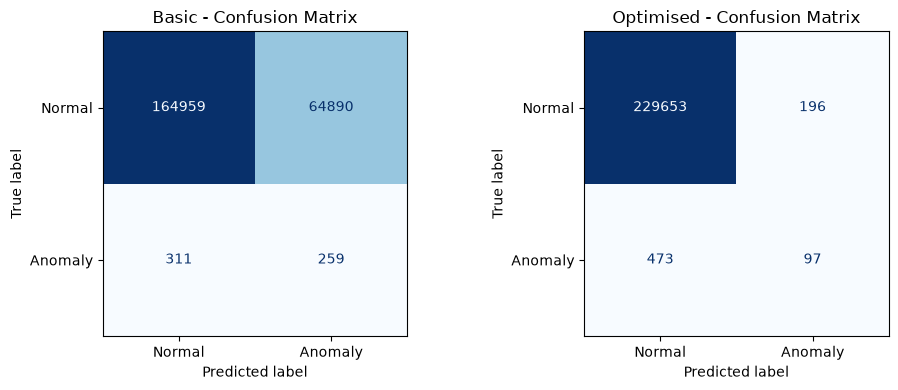

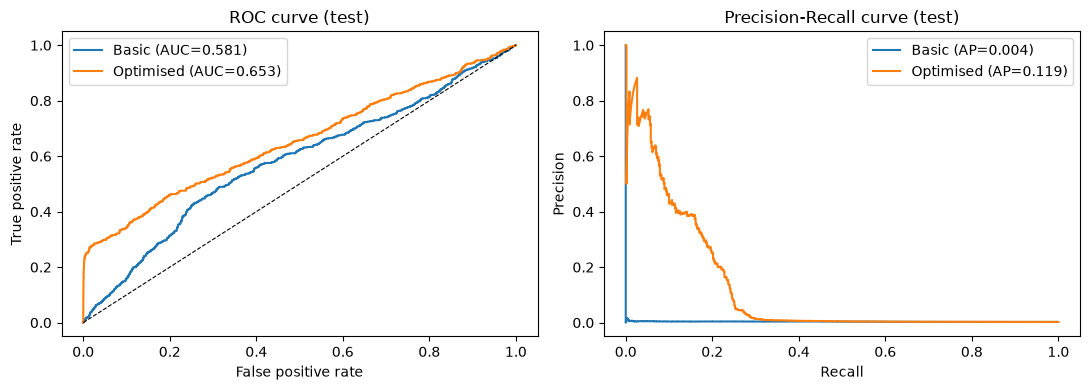

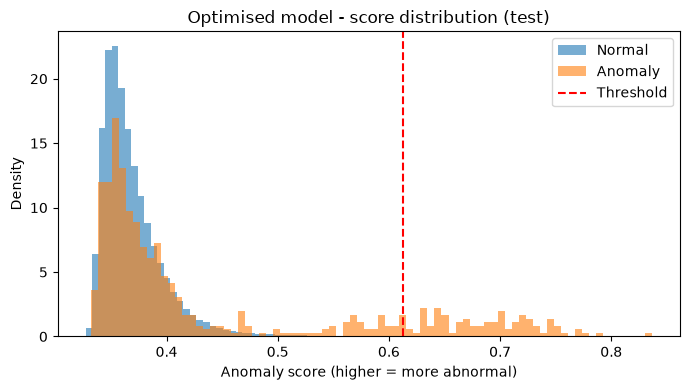


Saved: grid_search_results.csv, comparison_results.csv, per_disturbance_results.csv and 3 comparison PNG plots.


In [12]:
# ----------------------------------------------------------------------
# 7. PLOTS
# ----------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, title in zip(axes, [pred_basic, pred_opt], ["Basic", "Optimised"]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=[0, 1], display_labels=["Normal", "Anomaly"],
        cmap="Blues", ax=ax, colorbar=False, values_format="d")
    ax.set_title(f"{title} - Confusion Matrix")
plt.tight_layout()
plt.savefig("comparison_confusion_matrices.png", dpi=150)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for s, name in [(s_basic, "Basic"), (s_test, "Optimised")]:
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, s):.3f})")
    p, r, _ = precision_recall_curve(y_test, s)
    axes[1].plot(r, p, label=f"{name} (AP={average_precision_score(y_test, s):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate",
            title="ROC curve (test)")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curve (test)")
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.savefig("comparison_roc_pr_curves.png", dpi=150)

plt.figure(figsize=(7, 4))
plt.hist(s_test[y_test == 0], bins=80, alpha=0.6, density=True, label="Normal")
plt.hist(s_test[y_test == 1], bins=80, alpha=0.6, density=True, label="Anomaly")
plt.axvline(threshold, color="red", ls="--", label="Threshold")
plt.xlabel("Anomaly score (higher = more abnormal)")
plt.ylabel("Density")
plt.title("Optimised model - score distribution (test)")
plt.legend()
plt.tight_layout()
plt.savefig("optimised_score_distribution.png", dpi=150)
plt.show()

print("\nSaved: grid_search_results.csv, comparison_results.csv, "
      "per_disturbance_results.csv and 3 comparison PNG plots.")

In [13]:
import joblib
joblib.dump({"model": final_model, "scaler": scaler, "threshold": threshold,
             "feature_set": best_fs, "columns": list(F_train[best_fs].columns)},
            "optimised_model.joblib")

['optimised_model.joblib']